# 02 · Analysis: is group work a Prisoner's Dilemma, a Snowdrift game or neither?

**Input:** `data/clean/survey_clean.csv` (produced by `01_data_cleaning.ipynb`)
**Outputs:** figures in `outputs/figures/`, tables in `outputs/tables/`

**Research question.** In graded group work, does a student's payoff from cooperating depend on whether their
group-mates cooperate? Game theory gives three candidate answers:

| Game | Payoff ordering | What it predicts |
|---|---|---|
| Prisoner's Dilemma | T > R > P > S | Defecting pays whatever others do |
| Snowdrift (Chicken) | T > R > S > P | Best to do the opposite of others, so a stable mix of cooperators and free-riders |
| Harmony (no dilemma) | R > T and S > P | Cooperating pays whatever others do |

where **R** = I cooperate and others cooperate, **S** = I cooperate and others free-ride, **T** = I free-ride and
others cooperate, **P** = everyone free-rides.

**Plan and why it runs in this order:**
1. Build the two behaviour indices and check they measure something consistent (if the measuring tape is broken,
   nothing built on it can be trusted).
2. Describe the sample and the relationship between cooperation and competition.
3. Audit the payoffs in the original presentation.
4. Rebuild the payoff matrix with a design that maps onto the game, with uncertainty attached.
5. Use regression to test the same question with the full sample and controls.
6. Check that the conclusion survives different outcome measures.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.miscmodels.ordinal_model import OrderedModel

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "outputs" / "figures"
TAB = ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "clean" / "survey_clean.csv")

# One consistent chart style: thin marks, recessive axes, two colours used for identity only
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#1f1f1e", "#8a897f"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})
RNG_SEED = 42
N_BOOT = 5000
df.shape

(46, 31)

## 1. Build the indices and test their reliability

Each index is the average of three agreement items (1 to 5):

* **Cooperation Index:** Q8 enjoy group work, Q9 share notes, Q10 rely on others
* **Competition Index:** Q5 enjoy competition, Q6 important to outperform others, Q7 try harder when competing

**Why check reliability before using them:** averaging items only makes sense if they move together, meaning they
measure one underlying trait. **Cronbach's alpha** measures this. Rough guide: above 0.7 is good, 0.6 to 0.7 is
acceptable for a short exploratory scale, below 0.5 means the items are not measuring the same thing.

$$\alpha = \frac{k}{k-1}\left(1 - \frac{\sum_i \sigma^2_{i}}{\sigma^2_{total}}\right)$$

where $k$ is the number of items, $\sigma^2_i$ the variance of each item and $\sigma^2_{total}$ the variance of
the summed score.

In [2]:
COOP_ITEMS = ["q8_enjoy_group_work", "q9_share_notes", "q10_rely_on_others"]
COMP_ITEMS = ["q5_enjoy_competition", "q6_outperform_others", "q7_try_harder_competing"]

def cronbach_alpha(items: pd.DataFrame) -> float:
    items = items.dropna()
    k = items.shape[1]
    return k / (k - 1) * (1 - items.var(ddof=1).sum() / items.sum(axis=1).var(ddof=1))

df["coop_index"] = df[COOP_ITEMS].mean(axis=1)   # mean of available items, so one missing Q8 does not drop the student
df["comp_index"] = df[COMP_ITEMS].mean(axis=1)

reliability = pd.DataFrame({
    "items": [", ".join(COOP_ITEMS), ", ".join(COMP_ITEMS)],
    "cronbach_alpha": [cronbach_alpha(df[COOP_ITEMS]), cronbach_alpha(df[COMP_ITEMS])],
    "mean_inter_item_r": [df[COOP_ITEMS].corr().values[np.triu_indices(3, 1)].mean(),
                          df[COMP_ITEMS].corr().values[np.triu_indices(3, 1)].mean()],
}, index=["Cooperation Index", "Competition Index"]).round(3)
reliability.to_csv(TAB / "reliability.csv")
reliability

,items,cronbach_alpha,mean_inter_item_r
Cooperation Index,"q8_enjoy_group_work, q9_share_notes, q10_rely_...",0.333,0.136
Competition Index,"q5_enjoy_competition, q6_outperform_others, q7...",0.661,0.387


In [3]:
print("Inter-item correlations, cooperation items:")
print(df[COOP_ITEMS].corr().round(2))

Inter-item correlations, cooperation items:
                     q8_enjoy_group_work  q9_share_notes  q10_rely_on_others
q8_enjoy_group_work                 1.00            0.15                0.22
q9_share_notes                      0.15            1.00                0.03
q10_rely_on_others                  0.22            0.03                1.00


**Interpretation.** The Competition Index is acceptable for an exploratory three-item scale. The Cooperation Index is
**not reliable**: Q9 (sharing notes) barely correlates with the other two items. Enjoying group work, sharing notes
and being comfortable relying on others turn out to be different behaviours. This is a real finding, and it limits
every conclusion that uses the Cooperation Index. We keep it, but we also check key results item by item.

**Common mistake:** building an index by averaging items without ever testing whether they belong together.

**Comparison with the original Excel indices.** The rebuilt Competition Index matches exactly. The Cooperation Index
differs only for the three students whose invalid Q8 answers (7 and 8) were removed in cleaning.

In [4]:
diff = (df["coop_index"] - df["orig_Cooperation_Index"]).abs() > 1e-6
print("Cooperation Index rows that differ from Excel:", df.loc[diff, "respondent_id"].tolist())
print("Competition Index rows that differ from Excel:",
      int(((df["comp_index"] - df["orig_Competition_Index"]).abs() > 1e-6).sum()))

Cooperation Index rows that differ from Excel: [43, 44, 46]
Competition Index rows that differ from Excel: 0


## 2. Describe the sample

The original notebook plotted the 0/1 flags instead of the indices, which is why its histograms had only two bars.
Here we plot the continuous indices.

In [5]:
desc_cols = {"coop_index": "Cooperation Index", "comp_index": "Competition Index",
             "marks_band": "Marks band (1-6)", "relative_perf": "Relative performance (1-5)",
             "q14_motivation": "Motivation (1-5)", "study_with_peers": "Study with peers (0-5)"}
descr = df[list(desc_cols)].rename(columns=desc_cols).describe().T.round(2)
descr.to_csv(TAB / "descriptive_statistics.csv")
descr.to_latex(TAB / "descriptive_statistics.tex", float_format="%.2f",
               caption="Descriptive statistics (n = 46).", label="tab:descr")
descr

,count,mean,std,min,25%,50%,75%,max
Cooperation Index,46.0,3.54,0.75,1.00,3.00,3.67,4.00,5.0
Competition Index,46.0,3.70,0.82,1.33,3.33,3.67,4.33,5.0
Marks band (1-6),46.0,4.17,1.42,1.00,3.25,4.50,5.00,6.0
Relative performance (1-5),44.0,3.34,1.16,1.00,3.00,3.50,4.00,5.0
Motivation (1-5),46.0,3.89,1.16,1.00,3.25,4.00,5.00,5.0
Study with peers (0-5),46.0,2.15,1.32,0.00,2.00,2.00,3.00,5.0


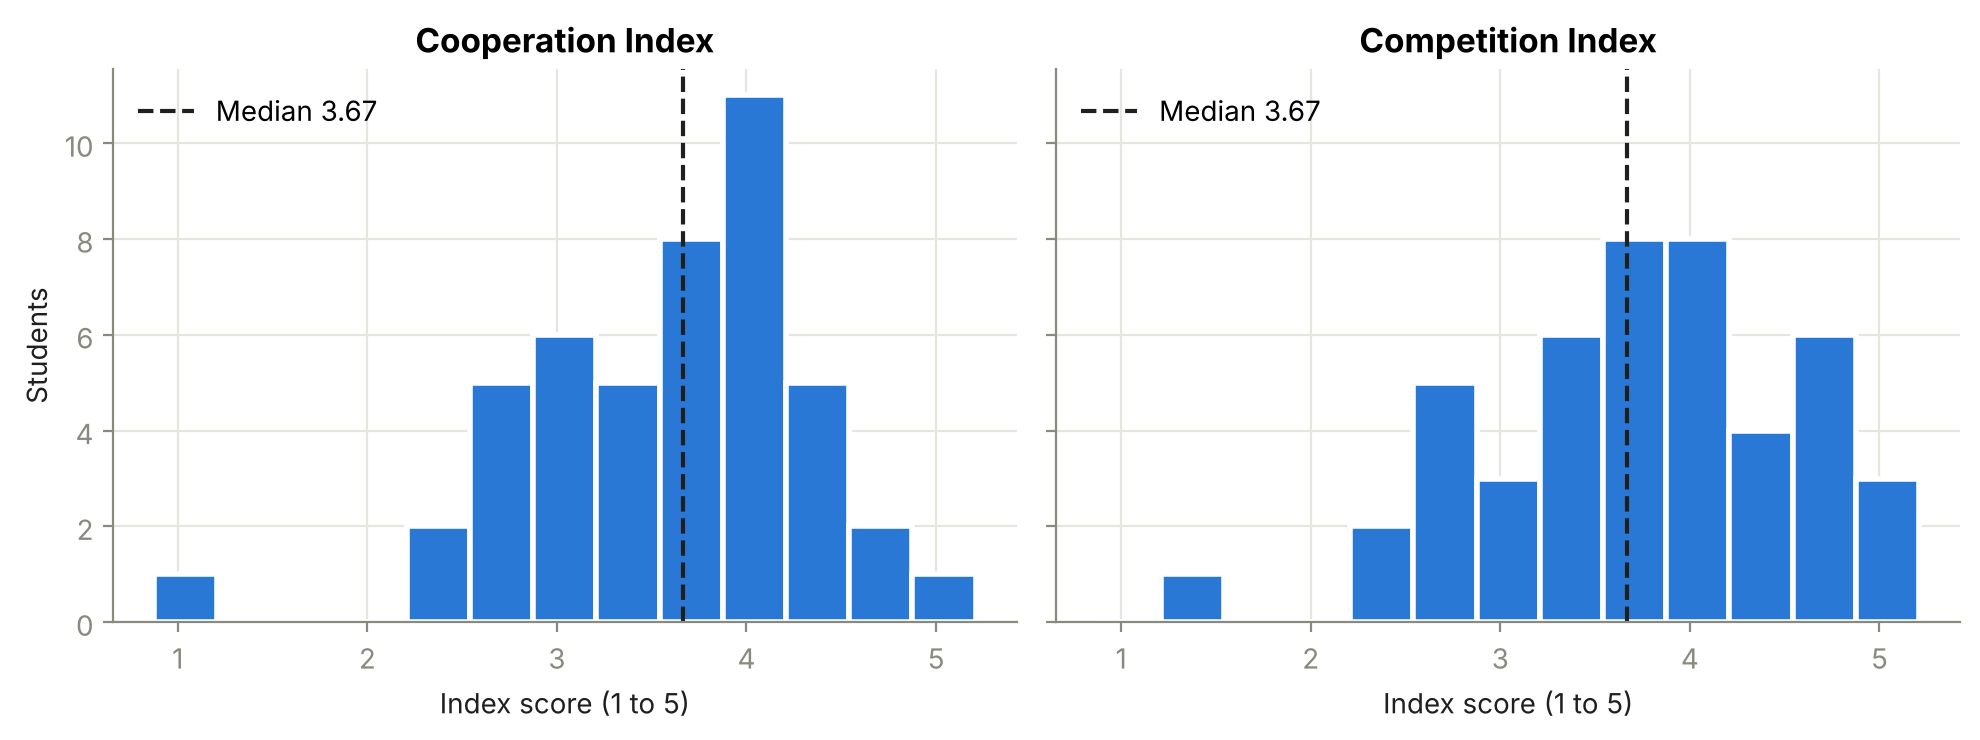

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
bins = np.arange(0.875, 5.3, 1/3)
for ax, col, title in zip(axes, ["coop_index", "comp_index"], ["Cooperation Index", "Competition Index"]):
    ax.hist(df[col].dropna(), bins=bins, color=BLUE, edgecolor="white", linewidth=2)
    ax.axvline(df[col].median(), color=INK, linewidth=1.5, linestyle="--", label=f"Median {df[col].median():.2f}")
    ax.legend(frameon=False, loc="upper left")
    ax.set_title(title)
    ax.set_xlabel("Index score (1 to 5)")
axes[0].set_ylabel("Students")
fig.tight_layout()
fig.savefig(FIG / "fig1_index_distributions.png", dpi=200)
plt.show()

### Are cooperative students less competitive?

**Hypothesis:** cooperation and competition are opposite ends of one trait, so the indices should be negatively
correlated. We test this with Pearson (linear), Spearman (rank-based, safer for ordinal survey data) and, to match the
original presentation, Fisher's exact test on the median-split table. Fisher is used instead of chi-square because
several expected cell counts are small.

In [7]:
df["high_coop"] = (df["coop_index"] >= df["coop_index"].median()).astype(int)
df["high_comp"] = (df["comp_index"] >= df["comp_index"].median()).astype(int)

crosstab = pd.crosstab(df["high_coop"], df["high_comp"]).rename_axis(index="High cooperation", columns="High competition")
odds, p_fisher = stats.fisher_exact(crosstab)
r, p_r = stats.pearsonr(df["coop_index"], df["comp_index"])
rho, p_rho = stats.spearmanr(df["coop_index"], df["comp_index"])

crosstab.to_csv(TAB / "crosstab_high_coop_high_comp.csv")
print(crosstab, "\n")
print(f"Fisher exact: odds ratio {odds:.2f}, p = {p_fisher:.3f}")
print(f"Pearson r = {r:.2f} (p = {p_r:.3f});  Spearman rho = {rho:.2f} (p = {p_rho:.3f})")

High competition   0   1
High cooperation        
0                  7  12
1                 10  17 

Fisher exact: odds ratio 0.99, p = 1.000
Pearson r = 0.21 (p = 0.167);  Spearman rho = 0.07 (p = 0.626)


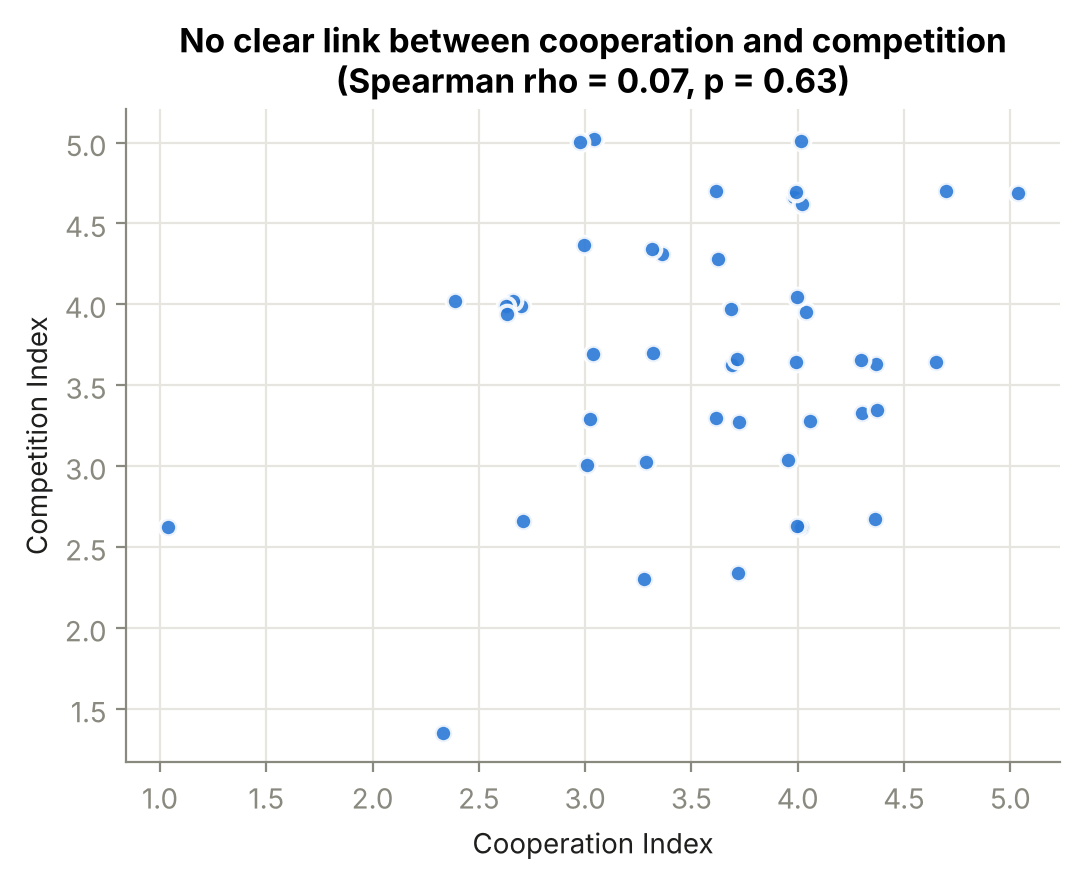

In [8]:
rng = np.random.default_rng(RNG_SEED)
jit = lambda n: rng.uniform(-0.06, 0.06, n)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(df["coop_index"] + jit(len(df)), df["comp_index"] + jit(len(df)),
           s=40, color=BLUE, edgecolor="white", linewidth=1.5, alpha=0.9)
ax.set_xlabel("Cooperation Index")
ax.set_ylabel("Competition Index")
ax.set_title(f"No clear link between cooperation and competition\n(Spearman rho = {rho:.2f}, p = {p_rho:.2f})")
fig.tight_layout()
fig.savefig(FIG / "fig2_coop_vs_comp.png", dpi=200)
plt.show()

**Interpretation.** There is no evidence that cooperative students are less competitive, or more. The two traits
look independent in this sample, so students can be high on both. This matters for the game-theory framing: a
"cooperator vs competitor" split is not a natural division of this class.

### Validity check: do the indices match what students say about themselves?

Q16 asked whether students learn better through cooperation, competition or both. If the indices measure what they
claim to, students who say "competition" should score higher on the Competition Index. Kruskal-Wallis compares the
three groups without assuming normality.

In [9]:
groups = ["Cooperation", "Competition", "Both"]
rows = []
for col, name in [("coop_index", "Cooperation Index"), ("comp_index", "Competition Index")]:
    samples = [df.loc[df["learns_better_with"] == g, col] for g in groups]
    h, p = stats.kruskal(*samples)
    rows.append({"index": name, **{f"mean ({g}, n={len(s)})": round(s.mean(), 2) for g, s in zip(groups, samples)},
                 "Kruskal-Wallis H": round(h, 2), "p": round(p, 3)})
validity = pd.DataFrame(rows).set_index("index")
validity.to_csv(TAB / "validity_check_q16.csv")
validity

,"mean (Cooperation, n=29)","mean (Competition, n=9)","mean (Both, n=7)",Kruskal-Wallis H,p
index,,,,,
Cooperation Index,3.70,3.44,3.38,1.94,0.379
Competition Index,3.59,4.30,3.52,7.32,0.026


**Interpretation.** The Competition Index passes: students who say they learn better through competition score
clearly higher (p < 0.05). The Cooperation Index does not separate the groups, which fits its low reliability.

## 3. Audit of the payoffs in the original presentation

The original slides reported **T = 4.67, R = 3.85, S = 3.15, P = 3.09** and concluded that the ordering
T > R > S > P "exactly matches" a Snowdrift game. These values were calculated in Excel and pasted into every row.
We check three things: can they be reproduced, are they on one scale and is the key gap (S > P) real?

**Finding 1: the outcome used for R, S and P overlaps with the cooperation items.** The Belonging Index turns out to be
the average of Q8, Q10 and study frequency. Q8 and Q10 are two of the three cooperation items, so cooperative
students score higher on "belonging" partly by construction. Using it as the payoff for a cooperation game is
circular.

In [10]:
# Excel used the raw Q8 (including the invalid 7s and 8s), so read it from the raw file
raw = pd.read_csv(ROOT / "data" / "raw" / "survey_responses_anonymised.csv")
q8_raw = raw["5) I enjoy working in groups and sharing ideas."]
study_excel = df["orig_Study_Frequency_with_Peers"]
belonging_rebuilt = (q8_raw + df["q10_rely_on_others"] + study_excel) / 3
print("Belonging Index = mean(Q8, Q10, study frequency):",
      np.allclose(belonging_rebuilt, df["orig_Belonging_Index"]))

Belonging Index = mean(Q8, Q10, study frequency): True


**Finding 2: T was not measured on the same scale.** The slide describes T as relative academic performance, while
R, S and P are Belonging scores. Comparing T with R is comparing two different measuring scales, so "T > R" carries no
meaning. A search over subgroup means shows 4.67 matches the average **motivation** score of a three-student
subgroup. The Excel formula is not available, so the exact definition cannot be confirmed.

**Finding 3: the S > P gap is not distinguishable from zero.** The values below are the best-matching
reconstruction of S and P from the Excel flags (they reproduce the slide values exactly). Note the subgroups share
17 students, which the slides did not mention.

In [11]:
orig_comp = df["orig_comp_index"] == 1
fr_yes_excel = df["orig_FREE_RIDING"] == 1
graded_often = df["orig_Grouip_Assignment_Involvement_frequency"] >= 3
S_mask, P_mask = orig_comp & fr_yes_excel, orig_comp & graded_often
B = df["orig_Belonging_Index"]
print(f"S reconstructed = {B[S_mask].mean():.4f} (n={S_mask.sum()}),  slide value 3.15")
print(f"P reconstructed = {B[P_mask].mean():.4f} (n={P_mask.sum()}),  slide value 3.0933")
print("Students in both groups:", (S_mask & P_mask).sum())

S reconstructed = 3.1500 (n=20),  slide value 3.15
P reconstructed = 3.0933 (n=25),  slide value 3.0933
Students in both groups: 17


**The bootstrap.** We cannot rerun the survey, so we simulate rerunning it: draw 46 students *with replacement* from
our 46, recalculate S - P and repeat 5,000 times. The spread of those 5,000 differences shows how much S - P would
move from sample to sample by chance alone. If the middle 95% of that spread includes zero, the data cannot tell us
whether S is really above P. Resampling whole students (rows) keeps the overlap between the two groups intact.

In [12]:
def bootstrap(data, stat_fn, n_boot=N_BOOT, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    n = len(data)
    return np.array([stat_fn(data.iloc[rng.integers(0, n, n)]) for _ in range(n_boot)])

def s_minus_p(d):
    comp = d["orig_comp_index"] == 1
    b = d["orig_Belonging_Index"]
    return (b[comp & (d["orig_FREE_RIDING"] == 1)].mean()
            - b[comp & (d["orig_Grouip_Assignment_Involvement_frequency"] >= 3)].mean())

boot_sp = bootstrap(df, s_minus_p)
ci_sp = np.nanpercentile(boot_sp, [2.5, 97.5])
share_sp = np.nanmean(boot_sp > 0)
print(f"Observed S - P = {s_minus_p(df):.3f}")
print(f"95% bootstrap interval: [{ci_sp[0]:.2f}, {ci_sp[1]:.2f}]")
print(f"Share of resamples where S > P: {share_sp:.0%}")

Observed S - P = 0.057
95% bootstrap interval: [-0.23, 0.35]
Share of resamples where S > P: 64%


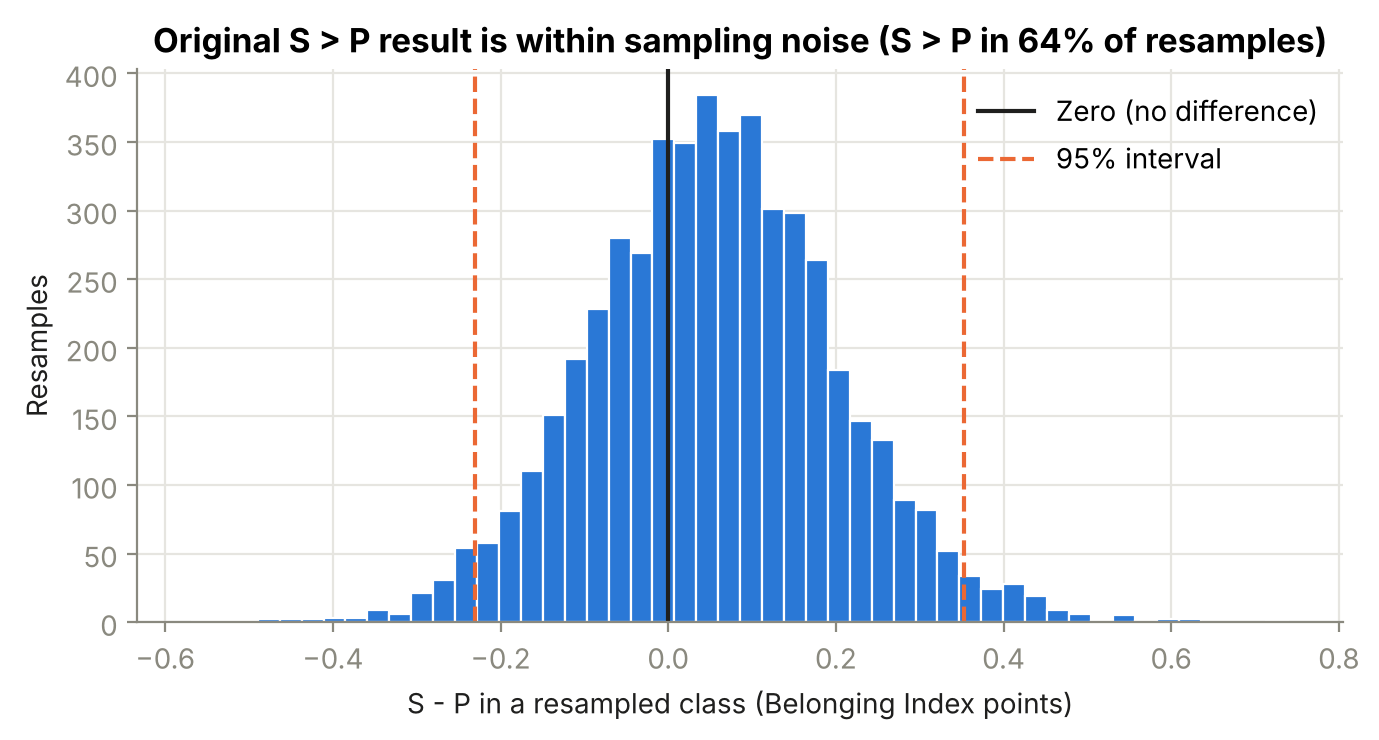

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(boot_sp, bins=50, color=BLUE, edgecolor="white", linewidth=0.8)
ax.axvline(0, color=INK, linewidth=1.5, label="Zero (no difference)")
for k, x in enumerate(ci_sp):
    ax.axvline(x, color=ORANGE, linewidth=1.5, linestyle="--", label="95% interval" if k == 0 else None)
ax.legend(frameon=False, loc="upper right")
ax.set_xlabel("S - P in a resampled class (Belonging Index points)")
ax.set_ylabel("Resamples")
ax.set_title(f"Original S > P result is within sampling noise (S > P in {share_sp:.0%} of resamples)")
fig.tight_layout()
fig.savefig(FIG / "fig3_original_s_minus_p_bootstrap.png", dpi=200)
plt.show()

**Conclusion of the audit.** The original Snowdrift conclusion rests on payoffs that mix scales, use an outcome that
overlaps with the grouping variable and differ by an amount well inside sampling noise. The original deck's
conclusion is therefore not supported, which is why the next section rebuilds the test.

## 4. Rebuilt payoff matrix

**Design (domain decisions, each open to challenge):**

* **My action:** cooperate = Cooperation Index at or above the median; defect = below the median.
* **Others' action:** Q13 "Have you observed free-riding?" Yes means group-mates defected; No means they cooperated.
  The 7 "Not Sure" answers are excluded here and tested separately in section 5.
* **Payoff:** self-reported marks band (1 = below 50% up to 6 = above 90%). Grades are the real payoff of graded
  group work, and this measure is not built from any of the cooperation items, which avoids the circularity found
  above.
* **One outcome for all four cells,** so the cells can be compared with each other.

| | Others cooperate (no free-riding) | Others defect (free-riding) |
|---|---|---|
| **I cooperate** | R | S |
| **I defect** | T | P |

In [14]:
game = df[df["free_riding"].notna()].copy()
CELL = {(1, 0): "R", (1, 1): "S", (0, 0): "T", (0, 1): "P"}
game["cell"] = [CELL[(hc, int(fr))] for hc, fr in zip(game["high_coop"], game["free_riding"])]

def cell_means(d, outcome="marks_band"):
    return d.groupby("cell")[outcome].mean().reindex(["R", "S", "T", "P"])

payoff = game.groupby("cell")["marks_band"].agg(["mean", "count"]).reindex(["R", "S", "T", "P"])

boot_cells = bootstrap(game, lambda d: cell_means(d).values)
payoff["ci_low"] = np.nanpercentile(boot_cells, 2.5, axis=0)
payoff["ci_high"] = np.nanpercentile(boot_cells, 97.5, axis=0)
payoff = payoff.round(2)
payoff.to_csv(TAB / "payoff_matrix_rebuilt.csv")
payoff

,mean,count,ci_low,ci_high
cell,,,,
R,5.50,2,5.00,6.00
S,4.52,21,4.05,4.96
T,3.67,6,2.00,5.00
P,4.10,10,3.00,5.15


**Read the `count` column first.** Only 8 students reported no free-riding, so the R and T cells hold 2 and 6
students. A mean of two people is close to an anecdote, and its interval shows that.

Now we test each ordering that separates the games, again with the bootstrap. A share near 50% means the data
cannot tell; a share near 100% or 0% means the ordering is consistent across resamples.

In [15]:
R, S, T, P = boot_cells.T
valid = ~np.isnan(boot_cells).any(axis=1)
orderings = pd.DataFrame({
    "comparison": ["T > R", "R > P", "P > S", "S > P"],
    "needed for": ["PD and Snowdrift", "PD and Snowdrift", "Prisoner's Dilemma", "Snowdrift"],
    "observed difference": [payoff.loc["T", "mean"] - payoff.loc["R", "mean"],
                            payoff.loc["R", "mean"] - payoff.loc["P", "mean"],
                            payoff.loc["P", "mean"] - payoff.loc["S", "mean"],
                            payoff.loc["S", "mean"] - payoff.loc["P", "mean"]],
    "share of resamples where true": [np.mean(T[valid] > R[valid]), np.mean(R[valid] > P[valid]),
                                      np.mean(P[valid] > S[valid]), np.mean(S[valid] > P[valid])],
}).round(2)
print(f"Resamples with all four cells filled: {valid.mean():.0%}")
orderings.to_csv(TAB / "payoff_orderings_bootstrap.csv", index=False)
orderings

Resamples with all four cells filled: 86%


,comparison,needed for,observed difference,share of resamples where true
0,T > R,PD and Snowdrift,-1.83,0.01
1,R > P,PD and Snowdrift,1.40,0.98
2,P > S,Prisoner's Dilemma,-0.42,0.25
3,S > P,Snowdrift,0.42,0.75


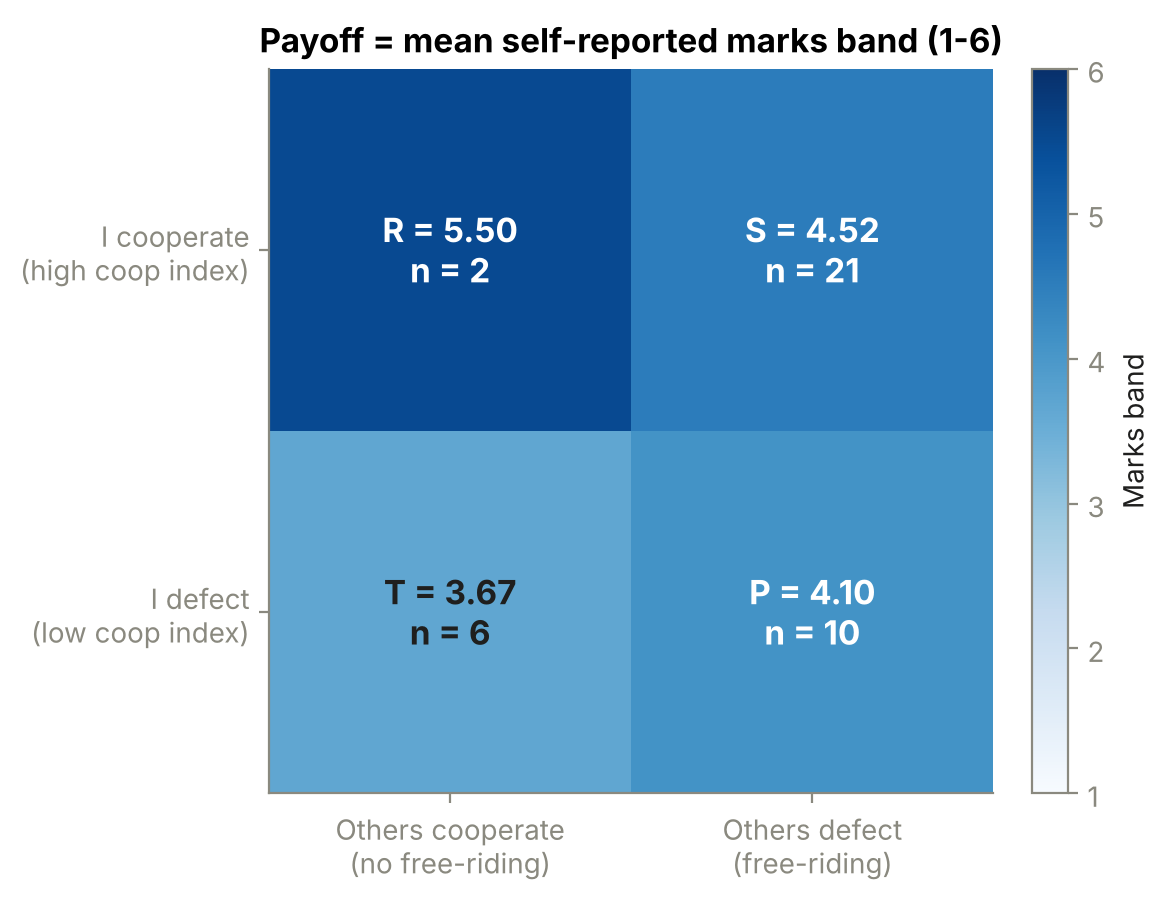

In [16]:
mat = np.array([[payoff.loc["R", "mean"], payoff.loc["S", "mean"]],
                [payoff.loc["T", "mean"], payoff.loc["P", "mean"]]])
cnt = np.array([[payoff.loc["R", "count"], payoff.loc["S", "count"]],
                [payoff.loc["T", "count"], payoff.loc["P", "count"]]]).astype(int)
lab = [["R", "S"], ["T", "P"]]

fig, ax = plt.subplots(figsize=(6, 4.6))
im = ax.imshow(mat, cmap="Blues", vmin=1, vmax=6)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{lab[i][j]} = {mat[i, j]:.2f}\nn = {cnt[i, j]}", ha="center", va="center",
                fontsize=12, color="white" if mat[i, j] > 4 else INK, fontweight="bold")
ax.set_xticks([0, 1], ["Others cooperate\n(no free-riding)", "Others defect\n(free-riding)"])
ax.set_yticks([0, 1], ["I cooperate\n(high coop index)", "I defect\n(low coop index)"])
ax.grid(False)
ax.set_title("Payoff = mean self-reported marks band (1-6)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Marks band")
fig.tight_layout()
fig.savefig(FIG / "fig4_payoff_matrix_rebuilt.png", dpi=200)
plt.show()

**Interpretation.** In both columns the cooperators report higher marks than the defectors (R > T and S > P), which is
the pattern of a **Harmony game**, where cooperating pays whatever others do. That is the opposite of what both the
Prisoner's Dilemma and Snowdrift require (T > R). However, the "others cooperate" column rests on 8 students, so the
matrix alone is too thin to settle the question. Section 5 asks the same question using every student at once.

## 5. Regression: does the return to cooperating depend on whether others free-ride?

The 2x2 matrix throws information away twice: it splits a continuous index at the median and it splits the sample
into four small cells. Regression uses the full index and all students together, and lets us hold competitiveness and
year of study constant.

$$\text{marks}_i = \beta_0 + \beta_1\,\text{coop}_i + \beta_2\,\text{comp}_i + \beta_3\,\text{freeride}_i
+ \beta_4\,(\text{coop}_i \times \text{freeride}_i) + \beta_5\,\text{year2}_i + \varepsilon_i$$

* $\beta_1$ is the payoff to cooperating when group-mates do not free-ride.
* $\beta_4$ is the game-theory test. In a Prisoner's Dilemma or Snowdrift game the payoff to cooperating changes
  depending on what others do, so $\beta_4$ should be clearly non-zero.

**Choices:** robust (HC3) standard errors, because with 46 students we cannot assume equal error variance and HC3 is
the version designed for small samples. The "Not Sure" group gets its own dummy so those students stay in the model
without being forced into yes or no.

In [17]:
reg = df.dropna(subset=["marks_band", "coop_index", "comp_index"]).copy()
reg["fr_yes"] = (reg["free_riding_text"] == "Yes").astype(int)
reg["fr_unsure"] = reg["free_riding_unsure"]
reg["year2"] = (reg["year_of_study"] == 2).astype(int)

# Centre the indices so beta_1 is the effect at an average level of free-riding exposure, which is easier to read
for c in ["coop_index", "comp_index"]:
    reg[c + "_c"] = reg[c] - reg[c].mean()

m_main = smf.ols("marks_band ~ coop_index_c + comp_index_c + fr_yes + fr_unsure + year2", data=reg).fit(cov_type="HC3")
m_int = smf.ols("marks_band ~ coop_index_c * fr_yes + comp_index_c + fr_unsure + year2", data=reg).fit(cov_type="HC3")
print(m_main.summary())

                            OLS Regression Results                            
Dep. Variable:             marks_band   R-squared:                       0.275
Model:                            OLS   Adj. R-squared:                  0.184
Method:                 Least Squares   F-statistic:                     2.478
Date:                Sat, 07 Nov 2026   Prob (F-statistic):             0.0479
Time:                        19:44:05   Log-Likelihood:                -73.468
No. Observations:                  46   AIC:                             158.9
Df Residuals:                      40   BIC:                             169.9
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        4.4003      0.764      5.761   

In [18]:
print(m_int.summary().tables[1])
print(f"\nInteraction coop x free-riding: coef = {m_int.params['coop_index_c:fr_yes']:.2f}, "
      f"p = {m_int.pvalues['coop_index_c:fr_yes']:.2f}")

                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               4.2520      0.708      6.009      0.000       2.865       5.639
coop_index_c            0.4358      0.903      0.483      0.629      -1.334       2.205
fr_yes                 -0.0885      0.719     -0.123      0.902      -1.499       1.322
coop_index_c:fr_yes     0.3111      1.011      0.308      0.758      -1.670       2.292
comp_index_c            0.2091      0.436      0.479      0.632      -0.646       1.065
fr_unsure              -1.0260      1.056     -0.972      0.331      -3.095       1.043
year2                   0.8570      0.690      1.243      0.214      -0.495       2.209

Interaction coop x free-riding: coef = 0.31, p = 0.76


**Robustness: ordered logit.** The marks band is ordered categories, not a true number, so OLS treats the gap from
band 1 to 2 as equal to the gap from 5 to 6. An ordered logit makes no such assumption. If both models agree on sign
and significance, the OLS conclusion is not an artefact of that assumption.

In [19]:
om = OrderedModel(reg["marks_band"], reg[["coop_index", "comp_index", "fr_yes", "fr_unsure", "year2"]],
                  distr="logit").fit(method="bfgs", disp=False)
ologit = pd.DataFrame({"coef": om.params, "p": om.pvalues}).loc[["coop_index", "comp_index", "fr_yes", "fr_unsure", "year2"]]
ologit["odds_ratio"] = np.exp(ologit["coef"])
ologit.round(3)

,coef,p,odds_ratio
coop_index,0.940,0.027,2.559
comp_index,0.378,0.378,1.460
fr_yes,-0.329,0.689,0.720
fr_unsure,-1.841,0.085,0.159
year2,1.711,0.056,5.533


In [20]:
def tidy(model, name):
    keep = [k for k in model.params.index if k != "Intercept"]
    return pd.DataFrame({"model": name, "coef": model.params[keep], "robust_se": model.bse[keep],
                         "p": model.pvalues[keep]}).round(3)

reg_table = pd.concat([tidy(m_main, "OLS main effects"), tidy(m_int, "OLS with interaction"),
                       ologit[["coef", "p"]].assign(model="Ordered logit").round(3)])
reg_table.to_csv(TAB / "regression_results.csv")
reg_table.to_latex(TAB / "regression_results.tex", float_format="%.3f",
                   caption="Determinants of self-reported marks band (HC3 robust standard errors).", label="tab:reg")
print(f"n = {int(m_main.nobs)}, R-squared (main OLS) = {m_main.rsquared:.2f}")

n = 46, R-squared (main OLS) = 0.27


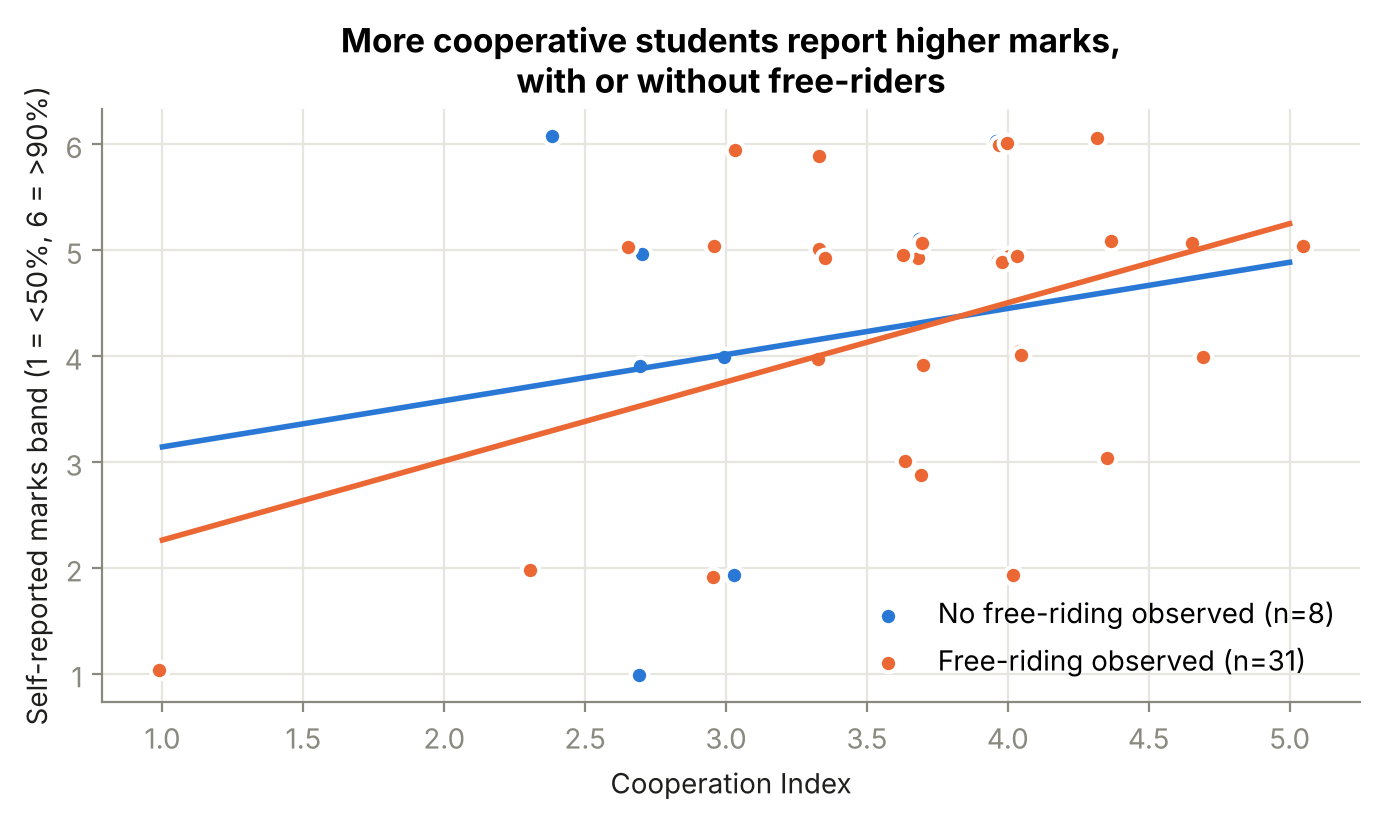

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.2))
rng = np.random.default_rng(RNG_SEED)
xs = np.linspace(reg["coop_index"].min(), reg["coop_index"].max(), 50)
for fr, colour, label in [(0, BLUE, "No free-riding observed"), (1, ORANGE, "Free-riding observed")]:
    sub = reg[(reg["fr_yes"] == fr) & (reg["fr_unsure"] == 0)]
    ax.scatter(sub["coop_index"] + rng.uniform(-0.05, 0.05, len(sub)), sub["marks_band"] + rng.uniform(-0.12, 0.12, len(sub)),
               s=40, color=colour, edgecolor="white", linewidth=1.5, label=f"{label} (n={len(sub)})")
    pred = m_int.predict(pd.DataFrame({"coop_index_c": xs - reg["coop_index"].mean(), "fr_yes": fr,
                                       "comp_index_c": 0, "fr_unsure": 0, "year2": 0}))
    ax.plot(xs, pred, color=colour, linewidth=2)
ax.set_xlabel("Cooperation Index")
ax.set_ylabel("Self-reported marks band (1 = <50%, 6 = >90%)")
ax.set_title("More cooperative students report higher marks,\nwith or without free-riders")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "fig5_marks_vs_cooperation.png", dpi=200)
plt.show()

## 6. Does the result survive other outcomes and item choices?

Two checks a sceptical reader would ask for:

1. **Different payoff measures:** relative performance (Q15) and motivation (Q14).
2. **Individual cooperation items** instead of the unreliable index, so we can see which behaviour drives the result.

In [22]:
rows = []
for outcome in ["marks_band", "relative_perf", "q14_motivation"]:
    m = smf.ols(f"{outcome} ~ coop_index + comp_index + fr_yes + fr_unsure + year2", data=reg).fit(cov_type="HC3")
    rows.append({"outcome": outcome, "n": int(m.nobs), "coop coef": m.params["coop_index"],
                 "coop p": m.pvalues["coop_index"], "free-riding coef": m.params["fr_yes"],
                 "free-riding p": m.pvalues["fr_yes"]})
for item in COOP_ITEMS:
    m = smf.ols(f"marks_band ~ {item} + comp_index + fr_yes + fr_unsure + year2", data=reg).fit(cov_type="HC3")
    rows.append({"outcome": f"marks_band (item: {item})", "n": int(m.nobs), "coop coef": m.params[item],
                 "coop p": m.pvalues[item], "free-riding coef": m.params["fr_yes"], "free-riding p": m.pvalues["fr_yes"]})
robust = pd.DataFrame(rows).set_index("outcome").round(3)
robust.to_csv(TAB / "robustness_checks.csv")
robust

,n,coop coef,coop p,free-riding coef,free-riding p
outcome,,,,,
marks_band,46,0.688,0.034,-0.217,0.781
relative_perf,44,0.534,0.029,0.044,0.941
q14_motivation,46,-0.282,0.205,0.018,0.963
marks_band (item: q8_enjoy_group_work),43,0.434,0.120,-0.311,0.766
marks_band (item: q9_share_notes),46,0.348,0.347,-0.190,0.802
marks_band (item: q10_rely_on_others),46,0.176,0.309,0.188,0.810


**Interpretation.** The cooperation effect shows up for both performance outcomes (marks band and relative
performance) but not for motivation. Free-riding is unrelated to every outcome. Item by item, all three cooperation
items point the same way (positive) but none is significant alone, which is what you would expect when three weak,
loosely related signals are averaged. That is a reason for caution, not a contradiction.

## 7. Conclusions

1. **The original Snowdrift conclusion does not hold up.** It relied on payoffs measured on different scales, an
   outcome partly built from the cooperation items, and an S > P gap (0.06) that sits well inside sampling noise.
2. **With a consistent payoff (self-reported marks), the data lean towards no dilemma at all.** Cooperators report
   higher marks than non-cooperators in both columns of the payoff matrix, and T > R (required by both the Prisoner's
   Dilemma and Snowdrift) holds in only about 1% of bootstrap resamples. The regression finds a positive link
   between the Cooperation Index and marks (about 0.7 of a marks band per index point, p around 0.03), confirmed by
   the ordered logit and by relative performance, while free-riding neither predicts marks nor changes the return
   to cooperating. That pattern matches a Harmony game. Treat it as suggestive: the link appears for the combined
   index but no single cooperation item is significant on its own, and the R cell holds only two students.
3. **Cooperation and competition are not opposites in this class.** The two indices are essentially unrelated.
4. **Free-riding is widespread** (31 of 46 students observed it) but shows no measurable link with marks.
5. **The relationship is not causal.** Stronger students may be the ones others want to work with, or self-reported
   marks may be inflated by the same optimism that produces high agreement scores.

## 8. Limitations

* **Small, single-class sample (n = 46)** with only 8 students reporting no free-riding, so the R and T cells are thin.
* **Self-reported outcomes.** Marks band and relative performance were not verified against grades.
* **Low reliability of the Cooperation Index** (alpha around 0.33). Results are reported item by item as a check.
* **"Others' action" is a proxy.** Observing free-riding at some point is not the same as a specific partner's
  choice in a specific assignment.
* **Cross-sectional survey.** We observe one moment, not repeated play, so dynamic strategies such as tit-for-tat
  cannot be tested.

## 9. Extensions

* Link survey answers to actual assignment grades (with consent).
* Use validated scales, such as established cooperative and competitive learning-orientation scales, to fix
  reliability.
* Run a short public-goods experiment in class to observe choices directly instead of asking about them.